# Projet ML — Classification binaire : **Diabetes Health Indicators**
*TAF MCE — IMT Atlantique — groupe de 3*

Jeu de données BRFSS 2015 (Kaggle) : prédire si une personne est diabétique / pré-diabétique (`Diabetes_binary = 1`) à partir de 21 indicateurs de santé et de mode de vie. Le même workflow (`ml_workflow.py`) que pour Spambase est appliqué ; la **difficulté propre** à ce jeu est le **fort déséquilibre des classes** (~14 % de positifs) et sa **taille** (253 680 lignes).

> **Règle suivie** : choix de modèles / hyperparamètres / seuil par validation croisée sur le **train uniquement** ; le test n'est utilisé qu'à la fin. Pour aller vite, la validation croisée et le réglage se font sur un **sous-échantillon stratifié du train** ; les modèles finaux sont réentraînés sur le train complet.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
import ml_workflow as ml

pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 100
SEED = ml.RANDOM_STATE
N_SUB = 30_000      # taille du sous-échantillon pour CV / réglage

## 1. Import et description des données  
*(responsable : **personne A**)*

In [2]:
# TODO personne A

# Loading
df_diabetes = ml.load_diabetes()

# what it looks like
display(df_diabetes.head())

# Dimension
print("Dimensions :", df_diabetes.shape)

# General description
display(
    ml.describe_dataset(
        df_diabetes,
        "Diabetes_binary"
    )
)

# Target distribution
display(
    df_diabetes["Diabetes_binary"].value_counts()
)

# percentage distribution
display(
    df_diabetes["Diabetes_binary"]
    .value_counts(normalize=True)
    .mul(100)
)


X_diabetes, y_diabetes = ml.split_features_target(
    df_diabetes,
    "Diabetes_binary"
)

print("X :", X_diabetes.shape)
print("y :", y_diabetes.shape)

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


Dimensions : (253680, 22)


n_rows                                                          253680
n_columns                                                           22
n_features                                                          21
n_missing_values                                                     0
n_duplicated_rows                                                24206
target                                                 Diabetes_binary
class_counts                                 {0.0: 218334, 1.0: 35346}
class_proportions    {0.0: 0.8606669820245979, 1.0: 0.1393330179754...
dtype: object

Diabetes_binary
0.0    218334
1.0     35346
Name: count, dtype: int64

Diabetes_binary
0.0    86.066698
1.0    13.933302
Name: proportion, dtype: float64

X : (253680, 21)
y : (253680,)


## 2. Pré-traitement  
*(responsable : **personne A**)*

In [3]:
# TODO personne A

# MCAR simulation of 5% missing values
X_diabetes_missing = ml.inject_missing_values(
    X_diabetes,
    frac=0.05,
    seed=SEED
)

# Stratified separation
X_train_diabetes, X_test_diabetes, y_train_diabetes, y_test_diabetes = ml.split_data(
    X_diabetes_missing,
    y_diabetes,
    test_size=0.2,
    seed=SEED
)

print("Train :", X_train_diabetes.shape)
print("Test :", X_test_diabetes.shape)

print("\nDistribution du train :")
display(y_train_diabetes.value_counts(normalize=True))

print("\nDistribution du test :")
display(y_test_diabetes.value_counts(normalize=True))

print("\nValeurs manquantes train :")
print(X_train_diabetes.isna().sum().sum())

print("\nValeurs manquantes test :")
print(X_test_diabetes.isna().sum().sum())

# Subsample for future cross-validation operations
X_sub, y_sub = ml.subsample(
    X_train_diabetes,
    y_train_diabetes,
    n=N_SUB,
    seed=SEED
)

print("\nSous-échantillon :", X_sub.shape)

display(y_sub.value_counts(normalize=True))

Train : (202944, 21)
Test : (50736, 21)

Distribution du train :


Diabetes_binary
0.0    0.860666
1.0    0.139334
Name: proportion, dtype: float64


Distribution du test :


Diabetes_binary
0.0    0.860671
1.0    0.139329
Name: proportion, dtype: float64


Valeurs manquantes train :
213153

Valeurs manquantes test :
53211

Sous-échantillon : (30000, 21)


Diabetes_binary
0.0    0.860667
1.0    0.139333
Name: proportion, dtype: float64

## 3. Gestion du déséquilibre  
*(responsable : **personne C**)*

In [4]:
# TODO personne C
print(y_train_diabetes.value_counts(normalize=True).round(3))

# Classifieur naïf (« toujours non ») : C'est la référence à battre
dummy = Pipeline([("model", DummyClassifier(strategy="prior"))]).fit(X_train_diabetes, y_train_diabetes)
base = ml.evaluate_model(dummy, X_test_diabetes, y_test_diabetes)   # roc_auc = 0.5, pr_auc = prévalence
pd.Series(base, name="Dummy (toujours non)").round(3)


Diabetes_binary
0.0    0.861
1.0    0.139
Name: proportion, dtype: float64


accuracy             0.861
balanced_accuracy    0.500
precision            0.000
recall               0.000
f1                   0.000
mcc                  0.000
roc_auc              0.500
pr_auc               0.139
Name: Dummy (toujours non), dtype: float64

In [5]:
# Effet de class_weight (Cross-validation sur le sous-échantillon du train, pas sur le test)
# On exclut le SVM car il est trop lent sur ces volumes
scoring = ("f1", "average_precision", "balanced_accuracy")
cv_nw = ml.cross_validate_models(ml.get_models(include_svm=False), X_sub, y_sub, cv=3, scoring=scoring)
cv_w  = ml.cross_validate_models(ml.get_models(class_weight="balanced", include_svm=False), X_sub, y_sub, cv=3, scoring=scoring)
pd.concat({"sans pondération": cv_nw, "class_weight=balanced": cv_w}).round(3)

f1_mean  f1_std  average_precision_mean  average_precision_std  balanced_accuracy_mean  balanced_accuracy_std  fit_time_s
sans pondération      lr     0.233   0.010                   0.398                  0.012                   0.564                  0.004       0.143
                      rf     0.201   0.008                   0.363                  0.009                   0.553                  0.003       1.799
                      hgb    0.240   0.018                   0.411                  0.014                   0.567                  0.006       0.527
class_weight=balanced lr     0.438   0.008                   0.398                  0.013                   0.740                  0.008       0.190
                      rf     0.392   0.003                   0.355                  0.007                   0.646                  0.003       1.755
                      hgb    0.436   0.002                   0.415                  0.012                   0.742                  0.000       0.544

## 4. Comparaison de plusieurs méthodes (CV sur le sous-échantillon, classes pondérées)  
*(responsable : **personne B**)*

In [6]:
# TODO personne B

models = ml.get_models(class_weight="balanced", include_svm=False, random_state=SEED)
cv_table = ml.cross_validate_models(
    models,
    X_sub,
    y_sub,
    cv=5,
    scoring=("f1", "roc_auc", "average_precision"),
)
display(cv_table.round(3).sort_values("average_precision_mean", ascending=False))

,f1_mean,f1_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,fit_time_s
hgb,0.435,0.006,0.820,0.009,0.416,0.023,0.807
lr,0.436,0.010,0.817,0.010,0.398,0.019,0.244
rf,0.394,0.019,0.797,0.009,0.355,0.019,3.039


## 5. Sélection de variables  
*(responsable : **personne B**)*

In [7]:
# TODO personne B

selector_model = LogisticRegression(
    class_weight="balanced", max_iter=1000, random_state=SEED
)
selector_table = ml.compare_feature_selectors(
    selector_model,
    X_sub,
    y_sub,
    methods=("anova", "mutual_info", "l1", "rf"),
    k_values=(5, 10, 15),
    cv=5,
    scoring="average_precision",
)
display(selector_table.round(3).sort_values("average_precision_mean", ascending=False))

pca_table = ml.compare_pca(
    selector_model,
    X_sub,
    y_sub,
    pca_components=(None, 0.95),
    cv=5,
    scoring="average_precision",
)
display(pca_table.round(3).sort_values("average_precision_mean", ascending=False))


average_precision_mean  average_precision_std  fit_time_s
method      k                                                            
l1          15                   0.398                  0.018       0.343
            10                   0.397                  0.019       0.359
anova       15                   0.396                  0.018       0.261
mutual_info 15                   0.396                  0.018       2.767
anova       10                   0.394                  0.018       0.209
mutual_info 10                   0.394                  0.018       2.719
rf          15                   0.391                  0.019       2.995
l1          5                    0.389                  0.018       0.341
mutual_info 5                    0.387                  0.019       2.746
anova       5                    0.384                  0.017       0.157
rf          10                   0.377                  0.016       2.945
            5                    0.359                  0.018       3.090

,average_precision_mean,average_precision_std,fit_time_s
none,0.398,0.019,0.186
0.95,0.391,0.019,0.229


## 6. Réglage des hyperparamètres de HistGradientBoosting (sous-échantillon, critère PR-AUC)  
*(responsable : **personne B**)*

In [8]:
# TODO personne B

hgb = HistGradientBoostingClassifier(
    class_weight="balanced", random_state=SEED
)
hgb_pipe = ml.build_pipeline(hgb)
hgb_grid = ml.tune_model(
    hgb_pipe,
    {
        "model__learning_rate": [0.03, 0.1],
        "model__max_iter": [100, 200],
        "model__l2_regularization": [0.0, 1.0],
    },
    X_train_diabetes,
    y_train_diabetes,
    scoring="average_precision",
    cv=3,
    n_samples=N_SUB,
)
print("Meilleurs hyperparamètres :", hgb_grid.best_params_)
print("Meilleur score PR-AUC (CV sur sous-échantillon) :", round(hgb_grid.best_score_, 3))

Meilleurs hyperparamètres : {'model__l2_regularization': 1.0, 'model__learning_rate': 0.1, 'model__max_iter': 100}
Meilleur score PR-AUC (CV sur sous-échantillon) : 0.414


## 7. Entraînement final sur le train complet et évaluation sur le test  
*(responsable : **personne C**)*

In [9]:
# Modèle final : le meilleur de la section 4 (PR-AUC en CV), réglé en section 6.
# tune_model a déjà réentraîné le meilleur pipeline sur le train complet.
best_name = cv_table["average_precision_mean"].idxmax()
print("Meilleur modèle en CV (section 4) :", best_name)
assert best_name == "hgb", "Le modèle réglé en section 6 est HGB : adapter `final` si le meilleur est un autre modèle."
final = hgb_grid.best_estimator_

Meilleur modèle en CV (section 4) : hgb


In [10]:
# Seuil de décision appris sur le train complet (scores hors-échantillon), jamais sur le test
oof = ml.oof_scores(final, X_train_diabetes, y_train_diabetes, cv=3)
thr = ml.find_best_threshold(y_train_diabetes, oof, metric="f1")

res = pd.DataFrame({
    "baseline (toujours non)": base,
    "seuil par défaut": ml.evaluate_model(final, X_test_diabetes, y_test_diabetes),
    f"seuil optimisé ({thr:.2f})": ml.evaluate_model(final, X_test_diabetes, y_test_diabetes, threshold=thr),
}).round(3)
res

,baseline (toujours non),seuil par défaut,seuil optimisé (0.65)
accuracy,0.861,0.715,0.803
balanced_accuracy,0.500,0.747,0.721
precision,0.000,0.301,0.373
recall,0.000,0.792,0.608
f1,0.000,0.436,0.463
mcc,0.000,0.355,0.366
roc_auc,0.500,0.822,0.822
pr_auc,0.139,0.414,0.414


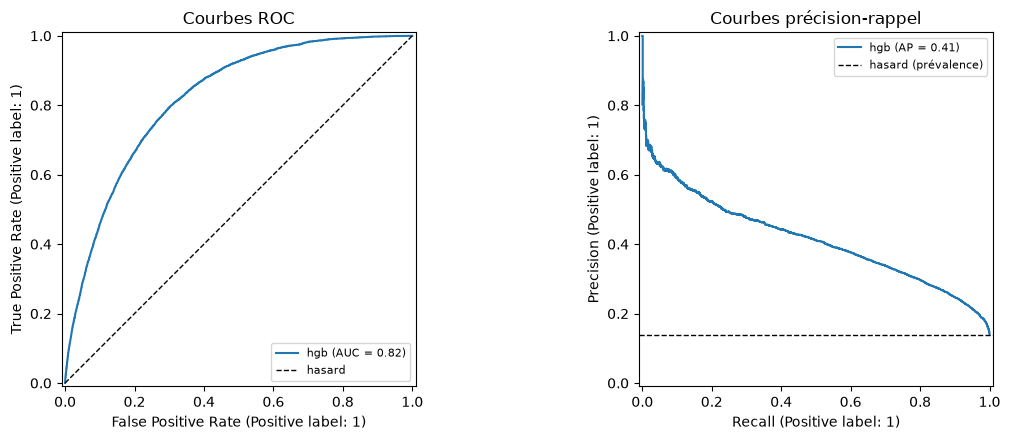

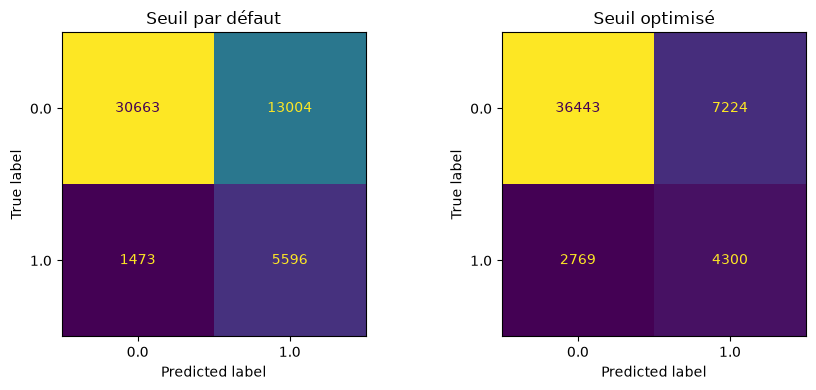

In [11]:
# Courbes ROC / PR et matrices de confusion du modèle final
ml.plot_roc_pr({best_name: final}, X_test_diabetes, y_test_diabetes)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
ml.plot_confusion(final, X_test_diabetes, y_test_diabetes, title="Seuil par défaut", ax=axes[0])
ml.plot_confusion(final, X_test_diabetes, y_test_diabetes, threshold=thr, title="Seuil optimisé", ax=axes[1])
plt.tight_layout()

## 8. Conclusions — Diabetes Health Indicators  
*(responsable : **personne C**)*

In [ ]:
# TODO personne C

**Méthode retenue : HistGradientBoosting (`class_weight="balanced"`, `learning_rate=0,1`, `max_iter=100`, `l2_regularization=1,0`), sur les 21 variables, sans ACP.**

**1. L'accuracy est trompeuse.** Seuls 13,9 % des individus sont diabétiques : le classifieur naïf « toujours non » obtient 0,861 d'accuracy mais détecte **0 %** des malades (rappel = 0, balanced accuracy = 0,5). Le modèle final a une accuracy *plus faible* (0,715 à 0,803) tout en étant bien plus utile. Nous jugeons donc les modèles sur la **PR-AUC** (référence de hasard = prévalence = 0,139), le F1, le rappel et la balanced accuracy.

**2. Effet de `class_weight` (CV sur le sous-échantillon).** La pondération n'améliore pas le classement des individus (PR-AUC : 0,411 → 0,415 pour HGB, 0,398 → 0,398 pour la régression logistique) mais **déplace le seuil implicite** : le F1 passe de 0,24 à 0,44 et la balanced accuracy de 0,57 à 0,74. Les modèles pondérés détectent beaucoup plus de malades.

**3. Choix du modèle (CV 5 plis, train).** PR-AUC : HGB 0,416 ± 0,023, régression logistique 0,398 ± 0,019, Random Forest 0,355 ± 0,019. HGB a la meilleure moyenne, mais **l'écart avec la régression logistique est dans le bruit** : celle-ci, plus simple et interprétable, reste une alternative défendable. Le réglage de HGB n'apporte pas de gain mesurable (0,414 contre 0,416 avec les valeurs par défaut).

**3 bis. Sélection de variables et ACP : aucun gain.** Avec la régression logistique, aucune sélection ne dépasse les 21 variables (0,398 pour `l1` k = 15, comme sans sélection) ; l'ACP à 95 % est légèrement moins bonne (0,391). Toutes les variables sont conservées.

**4. Performance finale (test, ≈ 50 700 individus).** ROC-AUC 0,822 ; **PR-AUC 0,414, soit environ 3 fois le hasard (0,139)**.

| | seuil 0,5 | seuil optimisé (0,65) |
|---|---|---|
| rappel | 0,792 | 0,608 |
| précision | 0,301 | 0,373 |
| F1 | 0,436 | 0,463 |
| balanced accuracy | 0,747 | 0,721 |
| accuracy | 0,715 | 0,803 |

Le modèle est pondéré (`class_weight`), donc son seuil F1-optimal est **plus haut** que 0,5 : le seuil optimisé réduit les fausses alertes (précision 0,30 → 0,37) au prix de 18 points de rappel. Le gain de F1 est faible (+ 0,03). ROC-AUC et PR-AUC sont identiques dans les deux cas : le seuil ne change pas la qualité du classement, seulement le point de fonctionnement.

**5. Quel seuil choisir ?** Cela dépend de l'usage, pas seulement du F1. Pour un **dépistage** (rater un malade coûte cher), on préfère le seuil par défaut : il retrouve ≈ 79 % des diabétiques, mais environ 7 alertes sur 10 sont de fausses alertes. Pour limiter les examens inutiles, le seuil optimisé est un meilleur compromis.

**Limites.** Pouvoir discriminant modeste (PR-AUC 0,41) : les 21 indicateurs sont auto-déclarés (enquête BRFSS 2015) ; un seul découpage ; valeurs manquantes simulées (MCAR, 5 %) ; **24 206 lignes dupliquées** non traitées, pouvant gonfler légèrement les scores si elles se retrouvent en train et en test ; critère F1 arbitraire pour le seuil ; réglage et CV réalisés sur un sous-échantillon de 30 000 lignes.

*Chiffres obtenus avec `SEED = 42` ; de légers écarts sont possibles selon la version de scikit-learn : relire ce texte après « Restart & Run All ».*
